# Đáp án mã · Bài 16 — Dữ liệu nhãn và học ít nhãn

Giải các bài tập **1, 2, 4** của Bài 16 bằng mã chạy được (bài 3 là viết thêm hàm gán nhãn, bài 5 cần PhoBERT nên chỉ có gợi ý bằng lời). Hãy tự làm trước, rồi đối chiếu. Ô đầu dựng lại dữ liệu và mô hình của Bài 16 (mã y hệt).

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")

ROOT = pathlib.Path.cwd()
while not (ROOT / "nlpvi").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.preprocessing import normalize

from nlpvi import load_splits, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)

TEN_LOP = ["tiêu cực", "trung tính", "tích cực"]
try:
    from datasets import load_dataset
    ds = load_dataset("uitnlp/vietnamese_students_feedback", revision="refs/convert/parquet")
    d = {k: ds[k].to_pandas().rename(columns={"sentence": "text", "sentiment": "y"})[["text", "y"]] for k in ("train", "validation", "test")}
    tr, te, NGUON = d["train"], d["test"], "UIT-VSFC"
except Exception as e:
    print(f"⚠ Không tải được UIT-VSFC ({type(e).__name__}); dùng bộ tổng hợp: số liệu sẽ khác.")
    a, b, c = load_splits(); m = {"tiêu cực": 0, "trung tính": 1, "tích cực": 2}
    f = lambda x: pd.DataFrame({"text": x["text"], "y": x["label"].map(m)})
    tr, te, NGUON = f(a), f(c), "tổng hợp"
ttr, ytr, tte, yte = tr["text"].tolist(), tr["y"].values, te["text"].tolist(), te["y"].values
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(ttr)
Xtr, Xte = vec.transform(ttr), vec.transform(tte)
mo_hinh = lambda cw="balanced": LogisticRegression(C=10, max_iter=2000, class_weight=cw)
mf1 = lambda y, p: f1_score(y, p, average="macro")

def kappa(a, b, K=3):
    a, b = np.asarray(a), np.asarray(b)
    po = np.mean(a == b)
    pe = float((np.bincount(a, minlength=K) / len(a) * np.bincount(b, minlength=K) / len(b)).sum())
    return (po - pe) / (1 - pe)

print(NGUON, "| train", len(ytr), "| test", len(yte))

UIT-VSFC | train 11426 | test 3166


## Bài tập 1 — κ theo mức độ cẩu thả của người gán

Ta tăng dần ba tham số của người gán mô phỏng (xác suất do dự sang "trung tính", đảo cực tính, và đẩy câu trung tính sang cực tính) rồi đo: độ chính xác của người gán so với chân lý, đồng thuận thô giữa hai người, κ tổng thể và κ riêng lớp "trung tính".

,độ chính xác của A,đồng thuận thô A–B,κ tổng thể,κ lớp trung tính,đồng thuận thô (trung tính vs không)
cấu hình,,,,,
"(0.0, 0.0, 0.0)",1.000,1.000,1.000,1.000,1.000
"(0.01, 0.003, 0.2)",0.979,0.961,0.928,0.584,0.967
"(0.03, 0.01, 0.4)",0.949,0.909,0.834,0.285,0.928
"(0.06, 0.02, 0.5)",0.905,0.831,0.702,0.096,0.872
"(0.1, 0.04, 0.6)",0.833,0.729,0.545,0.043,0.806
"(0.15, 0.06, 0.7)",0.775,0.636,0.411,-0.007,0.737
"(0.25, 0.1, 0.8)",0.637,0.493,0.226,0.010,0.634


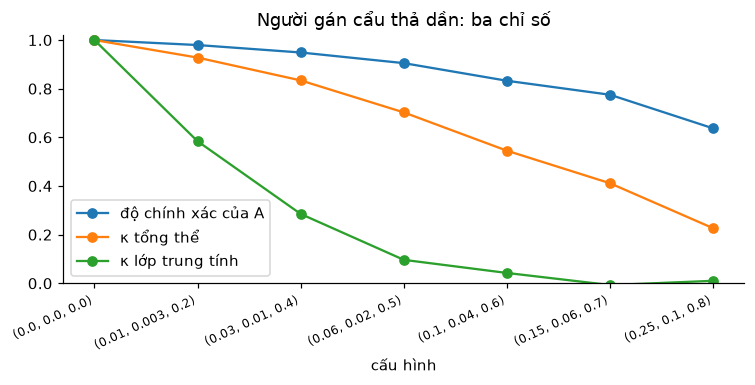

In [2]:
def nguoi_gan(y, rng, sang_trung_tinh, dao_cuc, trung_tinh_lech):
    out = y.copy(); u = rng.random(len(y)); cuc = y != 1
    out[cuc & (u < sang_trung_tinh)] = 1
    sai = cuc & (u >= sang_trung_tinh) & (u < sang_trung_tinh + dao_cuc); out[sai] = 2 - y[sai]
    tt = (y == 1) & (u < trung_tinh_lech); out[tt] = rng.choice([0, 2], tt.sum())
    return out

cau_hinh = [(0.00, 0.000, 0.00), (0.01, 0.003, 0.20), (0.03, 0.010, 0.40), (0.06, 0.020, 0.50), (0.10, 0.040, 0.60), (0.15, 0.060, 0.70), (0.25, 0.100, 0.80)]
rng = np.random.default_rng(0)
rows = []
for sa, dc, tl in cau_hinh:
    A, B = nguoi_gan(ytr, rng, sa, dc, tl), nguoi_gan(ytr, rng, sa, dc, tl)
    rows.append({"cấu hình": f"({sa}, {dc}, {tl})", "độ chính xác của A": np.mean(A == ytr), "đồng thuận thô A–B": np.mean(A == B),
                 "κ tổng thể": kappa(A, B), "κ lớp trung tính": kappa((A == 1).astype(int), (B == 1).astype(int), 2),
                 "đồng thuận thô (trung tính vs không)": np.mean((A == 1) == (B == 1))})
bang = pd.DataFrame(rows).set_index("cấu hình")
display(bang.round(3))
ax = bang.plot(y=["độ chính xác của A", "κ tổng thể", "κ lớp trung tính"], marker="o", figsize=(7, 3.6))
ax.set_ylim(0, 1.02); ax.set_xticks(range(len(bang))); ax.set_xticklabels(bang.index, rotation=25, ha="right", fontsize=8); ax.set_title("Người gán cẩu thả dần: ba chỉ số")
plt.tight_layout(); plt.show()

**Đọc kết quả (bài 1).** Khi người gán cẩu thả dần, độ chính xác của A giảm 0,98 → 0,95 → 0,91 → 0,83, κ tổng thể giảm 0,93 → 0,83 → 0,70 → 0,55, còn **κ của lớp "trung tính" sụp nhanh nhất**: 0,58 → 0,29 → 0,10 → 0,04 và về ≈ 0 khi người gán đúng ≈ 78%. Ví dụ ở cấu hình (0,06; 0,02; 0,5) người gán *đúng 90,5%*, đồng thuận thô nhị phân "trung tính / không" vẫn 0,87, nhưng κ lớp này chỉ 0,10. Lý do: với lớp chiếm 4%, khớp ngẫu nhiên kỳ vọng ở cấu hình này đã ≈ 0,86 nên đồng thuận thô gần như không chứa thông tin; κ chỉ "nhìn thấy" phần vượt trên mức đó. Ngay cả người gán rất tốt (đúng 97,9%, đồng thuận thô nhị phân 0,967) cũng chỉ có κ lớp hiếm 0,58. Vì vậy κ **theo từng lớp** là con số nên báo cáo, và κ của lớp hiếm giảm nhanh hơn nhiều so với độ chính xác chung.

## Bài tập 2 — Các kiểu nhiễu nhãn

Bốn kiểu nhiễu: **đối xứng** (chuyển sang một trong hai lớp còn lại), **đảo tiêu cực ↔ tích cực**, **cực tính → trung tính** (do dự), **trung tính → cực tính**. Với mỗi kiểu thử 3 mức $p$ và hai cách đặt trọng số lớp (`balanced` và không cân bằng). Điểm: macro-F1 trên test sạch (3 seed).

In [3]:
def sym(y, p, r):
    y2 = y.copy(); m = r.random(len(y)) < p; y2[m] = (y[m] + r.integers(1, 3, m.sum())) % 3; return y2
def dao_cuc(y, p, r):
    y2 = y.copy(); m = (r.random(len(y)) < p) & (y != 1); y2[m] = 2 - y[m]; return y2
def ve_trung_tinh(y, p, r):
    y2 = y.copy(); m = (r.random(len(y)) < p) & (y != 1); y2[m] = 1; return y2
def tu_trung_tinh(y, p, r):
    y2 = y.copy(); m = (r.random(len(y)) < p) & (y == 1); y2[m] = r.choice([0, 2], m.sum()); return y2

rows = []
for ten, f in [("đối xứng", sym), ("đảo tiêu cực ↔ tích cực", dao_cuc), ("cực tính → trung tính", ve_trung_tinh), ("trung tính → cực tính", tu_trung_tinh)]:
    for p in (0.1, 0.2, 0.4):
        a, b, ty_le = [], [], []
        for seed in range(3):
            y2 = f(ytr, p, np.random.default_rng(seed)); ty_le.append((y2 != ytr).mean())
            a.append(mf1(yte, mo_hinh().fit(Xtr, y2).predict(Xte))); b.append(mf1(yte, mo_hinh(None).fit(Xtr, y2).predict(Xte)))
        rows.append({"kiểu nhiễu": ten, "p": p, "tỉ lệ nhãn thật sự đổi": round(float(np.mean(ty_le)), 3), "balanced": round(float(np.mean(a)), 3), "không cân bằng lớp": round(float(np.mean(b)), 3)})
display(pd.DataFrame(rows).set_index(["kiểu nhiễu", "p"]))

tỉ lệ nhãn thật sự đổi  balanced  \
kiểu nhiễu              p                                       
đối xứng                0.1                   0.103     0.667   
                        0.2                   0.202     0.617   
                        0.4                   0.399     0.514   
đảo tiêu cực ↔ tích cực 0.1                   0.099     0.711   
                        0.2                   0.195     0.675   
                        0.4                   0.383     0.543   
cực tính → trung tính   0.1                   0.099     0.658   
                        0.2                   0.195     0.624   
                        0.4                   0.383     0.567   
trung tính → cực tính   0.1                   0.004     0.732   
                        0.2                   0.008     0.729   
                        0.4                   0.016     0.711   

                             không cân bằng lớp  
kiểu nhiễu              p                        
đối xứng                0.1               0.680  
                        0.2               0.644  
                        0.4               0.542  
đảo tiêu cực ↔ tích cực 0.1               0.685  
                        0.2               0.645  
                        0.4               0.517  
cực tính → trung tính   0.1               0.682  
                        0.2               0.649  
                        0.4               0.527  
trung tính → cực tính   0.1               0.703  
                        0.2               0.688  
                        0.4               0.661

**Đọc kết quả (bài 2).** Với cùng ≈ 20% nhãn bị đổi, macro-F1 (`balanced`) dao động theo *kiểu* nhiễu: đối xứng 0,617; đảo tiêu cực ↔ tích cực 0,675 (nhẹ nhất); cực tính → trung tính 0,624. Kiểu "trung tính → cực tính" chỉ đổi ≈ 1% số nhãn (lớp này chỉ 4%) nên gần như vô hại (0,729 ở p = 0,2; 0,711 ngay cả ở p = 0,4). **Cách đặt trọng số lớp làm đảo thứ tự**: với `balanced`, nhãn "trung tính" giả bị nhân trọng số lớn nên hai kiểu *sinh ra* "trung tính" (đối xứng, cực tính → trung tính) hại hơn so với không cân bằng lớp (0,617 và 0,624 so với 0,644 và 0,649); ngược lại với kiểu đảo tiêu cực ↔ tích cực thì `balanced` tốt hơn (0,675 so với 0,645) vì nhãn lớp hiếm vẫn sạch. Đây là một cách giải thích phù hợp với số liệu, chưa được kiểm chứng riêng.

## Bài tập 4 — Học tích cực theo lô đa dạng

Chọn 50 mẫu bất định nhất có thể gồm 50 câu *gần như giống nhau*. Biến thể **đa dạng**: chia kho chưa gán thành 50 cụm (`MiniBatchKMeans` trên TF-IDF → SVD 100 chiều) rồi lấy mẫu **bất định nhất ở mỗi cụm**. So với "độ tự tin thấp nhất" thông thường và chọn ngẫu nhiên: mỗi vòng thêm 50 nhãn đến 1.000, 5 seed.

99s


,ngẫu nhiên,bất định nhất,bất định + đa dạng
số nhãn,,,
100,0.531,0.543,0.535
200,0.567,0.566,0.579
400,0.588,0.611,0.615
600,0.613,0.642,0.641
800,0.625,0.657,0.658
1000,0.639,0.679,0.676


,tỉ lệ 'trung tính' trong 1000 nhãn đã chọn
ngẫu nhiên,0.042
bất định nhất,0.152
bất định + đa dạng,0.107


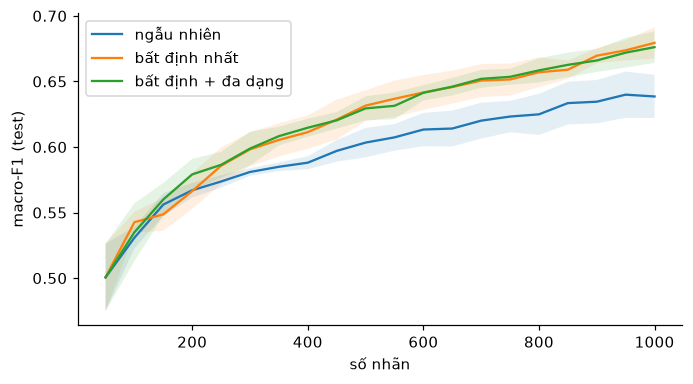

In [4]:
Z = normalize(TruncatedSVD(100, random_state=0).fit_transform(Xtr))

def hoc_tich_cuc(chien_luoc, seed, n0=50, buoc=50, tong=1000):
    r = np.random.default_rng(seed)
    khoi_tao = [i for c in range(3) for i in r.choice(np.where(ytr == c)[0], 5, replace=False)]
    da_gan = khoi_tao + list(r.choice(np.setdiff1d(np.arange(len(ytr)), khoi_tao), n0 - len(khoi_tao), replace=False))
    kho = np.setdiff1d(np.arange(len(ytr)), da_gan); duong = []
    while True:
        clf = mo_hinh().fit(Xtr[da_gan], ytr[da_gan]); duong.append((len(da_gan), mf1(yte, clf.predict(Xte))))
        if len(da_gan) >= tong: break
        if chien_luoc == "ngẫu nhiên":
            q = r.choice(kho, buoc, replace=False)
        else:
            bat_dinh = 1 - clf.predict_proba(Xtr[kho]).max(1)
            if chien_luoc == "bất định nhất":
                q = kho[np.argsort(-bat_dinh)[:buoc]]
            else:                                                       # đa dạng: bất định nhất trong mỗi cụm
                cum = MiniBatchKMeans(buoc, random_state=seed, n_init=1).fit_predict(Z[kho])
                q = np.array([kho[np.where(cum == c)[0][np.argmax(bat_dinh[cum == c])]] for c in np.unique(cum)])
        da_gan += list(q); kho = np.setdiff1d(kho, q)
    return duong, np.array(da_gan)

t0 = time.time()
CL = ["ngẫu nhiên", "bất định nhất", "bất định + đa dạng"]
kq, gan = {}, {}
for cl in CL:
    runs = [hoc_tich_cuc(cl, s) for s in range(5)]
    kq[cl] = np.array([[x[1] for x in r[0]] for r in runs]); gan[cl] = [r[1] for r in runs]
n_truc = [x[0] for x in runs[0][0]]
print(f"{time.time() - t0:.0f}s")
display(pd.DataFrame({cl: {n: round(kq[cl][:, n_truc.index(n)].mean(), 3) for n in (100, 200, 400, 600, 800, 1000)} for cl in CL}).rename_axis("số nhãn"))
display(pd.DataFrame({"tỉ lệ 'trung tính' trong 1000 nhãn đã chọn": {cl: round(float(np.mean([np.mean(ytr[g] == 1) for g in gan[cl]])), 3) for cl in CL}}))
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for cl in CL:
    m, s = kq[cl].mean(0), kq[cl].std(0); ax.plot(n_truc, m, label=cl); ax.fill_between(n_truc, m - s, m + s, alpha=0.12)
ax.set_xlabel("số nhãn"); ax.set_ylabel("macro-F1 (test)"); ax.legend(); plt.tight_layout(); plt.show()

**Đọc kết quả (bài 4).** Chọn theo lô **đa dạng** *không cho lợi ích rõ ràng* so với "bất định nhất" thông thường: ở 1.000 nhãn 0,676 so với 0,679 (cả hai hơn ngẫu nhiên 0,639 khoảng 0,04). Ở 200 nhãn nó nhỉnh hơn (0,579 so với 0,566) nhưng chênh lệch cỡ độ lệch chuẩn giữa các seed (≈ 0,01) nên chưa đủ để kết luận. Khác biệt rõ nhất là **thành phần mẫu**: lô đa dạng chọn ít mẫu lớp hiếm hơn (10,7% "trung tính" so với 15,2%) mà vẫn đạt điểm tương đương. Một cách đọc: ở bài toán này phần lớn lợi ích đến từ việc *tìm mẫu bất định*, còn ép đa dạng đổi lớp hiếm lấy độ phủ không gian mà không lợi thêm. (5 seed, một mô hình, một bộ dữ liệu.)

## Gợi ý cho các bài còn lại

- **Bài 3** (viết thêm hàm gán nhãn): để cải thiện F1 lớp "trung tính" bạn cần *chính các mẫu của lớp đó* trong tập dev; hãy tìm có chủ đích các câu chứa từ khóa của luật rồi gán thử để ước lượng độ chính xác của luật.
- **Bài 5** (học tích cực với PhoBERT): tinh chỉnh lại sau mỗi lô là khoản chi phí chính (Bài 10: ≈ 3,4 phút cho 11,4 nghìn câu); dùng lô lớn hơn, ít vòng hơn, và đo xem mẫu chọn theo TF-IDF có còn tốt cho PhoBERT không.